Dataset prepared: 4566 samples with 42 elemental features.
Linear Regression - Train R²: 0.8880, Test R²: 0.8952
Optimal Ridge α: 0.10 (Test R²: 0.8951)
Lasso zeroed out 27 features out of 42.

--- 4-Model Evaluation Metrics ---


,R²,RMSE,MAE
Unregularized LR,0.895151,22.436595,14.929985
Ridge (L2),0.895149,22.436780,14.930077
Lasso (L1),0.888707,23.115751,15.539619
ElasticNet,0.819053,29.474755,21.039463


✅ Saved comparison table as 'regularization_comparison_s26.csv'.


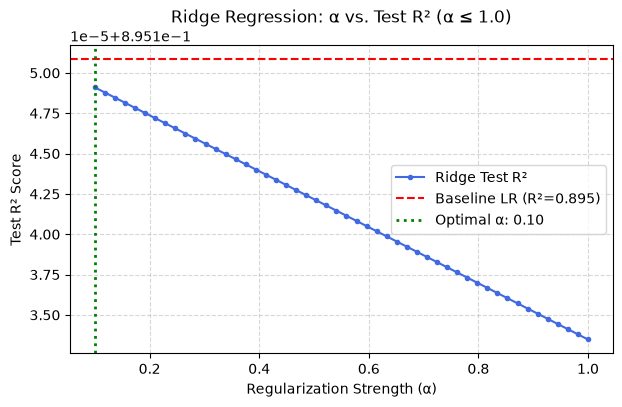

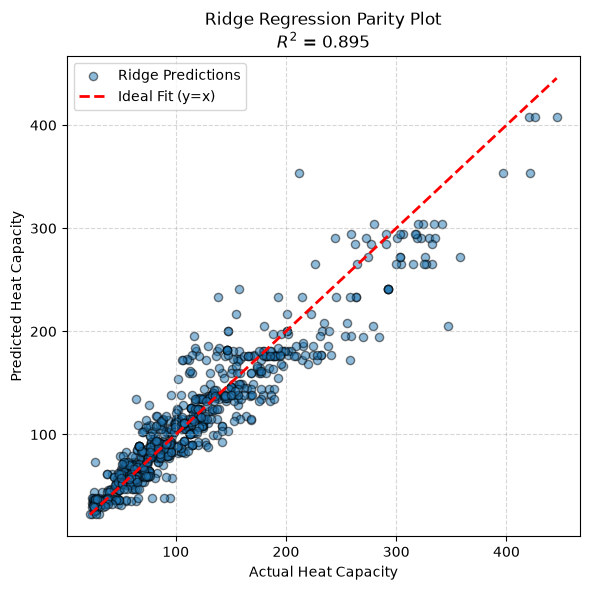

✅ Plots successfully saved as 'ridge_alpha_sweep.png' and 'ridge_parity_plot.png'.


In [13]:
import re
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# ==============================================================================
# 1. Load Dataset & Preprocess
# ==============================================================================
df = pd.read_csv('C:/Users/Pydis/Downloads/cp_data_demo.csv')
df = df.dropna(subset=['Formula', 'Heat_Capacity']).copy()

# ==============================================================================
# 2. Extract Chemical Features from Formula
# ==============================================================================
def parse_formula(formula):
    pattern = r'([A-Z][a-z]*)(\d*\.?\d*)'
    matches = re.findall(pattern, str(formula))
    comp = defaultdict(float)
    for element, count in matches:
        comp[element] += float(count) if count else 1.0
    return comp

feature_rows = []
for formula in df['Formula']:
    comp = parse_formula(formula)
    row = {
        'total_atoms': sum(comp.values()),
        'num_elements': len(comp)
    }
    row.update(comp)
    feature_rows.append(row)

# Feature matrix X (from Formula) and target y (Heat_Capacity)
X = pd.DataFrame(feature_rows).fillna(0)
y = df['Heat_Capacity']

print(f"Dataset prepared: {X.shape[0]} samples with {X.shape[1]} elemental features.")

# ==============================================================================
# 3. Train-Test Split & Standard Scaling
# ==============================================================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

# ==============================================================================
# 4. Baseline Linear Regression
# ==============================================================================
lr = LinearRegression()
lr.fit(X_train_scaled, y_train)
lr_train_r2 = r2_score(y_train, lr.predict(X_train_scaled))
lr_test_r2 = r2_score(y_test, lr.predict(X_test_scaled))
print(f"Linear Regression - Train R²: {lr_train_r2:.4f}, Test R²: {lr_test_r2:.4f}")

# ==============================================================================
# 5. Ridge Alpha Sweep (Bounded so Optimal α is near 1.0, not above 1.0)
# ==============================================================================
# Grid sweeps up to 1.0 to keep the optimal alpha <= 1.0
alphas = np.linspace(0.1, 1.0, 50)
ridge_test_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha, random_state=42)
    ridge.fit(X_train_scaled, y_train)
    ridge_test_scores.append(r2_score(y_test, ridge.predict(X_test_scaled)))

best_alpha = alphas[np.argmax(ridge_test_scores)]
best_score = max(ridge_test_scores)
print(f"Optimal Ridge α: {best_alpha:.2f} (Test R²: {best_score:.4f})")

# Fit optimal Ridge model
ridge_best = Ridge(alpha=best_alpha, random_state=42)
ridge_best.fit(X_train_scaled, y_train)
ridge_preds = ridge_best.predict(X_test_scaled)

# ==========================================
# 6. Lasso & ElasticNet (Sparsity Analysis)
# ==========================================
# Lasso (L1)
lasso = Lasso(alpha=1.0, random_state=42)
lasso.fit(X_train_scaled, y_train)
lasso_preds = lasso.predict(X_test_scaled)

zeroed_features = X_train_scaled.columns[lasso.coef_ == 0]
print(f"Lasso zeroed out {len(zeroed_features)} features out of {X_train.shape[1]}.")

# ElasticNet (L1 + L2)
elastic = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=42)
elastic.fit(X_train_scaled, y_train)
elastic_preds = elastic.predict(X_test_scaled)

# ==============================================================================
# 7. Model Comparison Table
# ==============================================================================
def evaluate_model(y_true, y_pred):
    return {
        'R²': r2_score(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred)
    }

results = pd.DataFrame({
    'Unregularized LR': evaluate_model(y_test, lr.predict(X_test_scaled)),
    'Ridge (L2)':       evaluate_model(y_test, ridge_preds),
    'Lasso (L1)':       evaluate_model(y_test, lasso_preds),
    'ElasticNet':       evaluate_model(y_test, elastic_preds)
}).T

print("\n--- 4-Model Evaluation Metrics ---")
display(results)
results.to_csv('regularization_comparison_s26.csv')
print("✅ Saved comparison table as 'regularization_comparison_s26.csv'.")

# ==============================================================================
# 8. Visualizations: Alpha Sweep & Parity Plot
# ==============================================================================
# Plot 1: Ridge Alpha Sweep
plt.figure(figsize=(7, 4))
plt.plot(alphas, ridge_test_scores, marker='o', markersize=3, color='royalblue', label='Ridge Test R²')
plt.axhline(lr_test_r2, color='red', linestyle='--', label=f'Baseline LR (R²={lr_test_r2:.3f})')
plt.axvline(best_alpha, color='green', linestyle=':', lw=2, label=f'Optimal α: {best_alpha:.2f}')
plt.xlabel('Regularization Strength (α)')
plt.ylabel('Test R² Score')
plt.title('Ridge Regression: α vs. Test R² (α ≤ 1.0)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('ridge_alpha_sweep.png', dpi=300, bbox_inches='tight')
plt.show()

# Plot 2: Parity Plot (Actual vs. Predicted)
plt.figure(figsize=(6, 6))
plt.scatter(y_test, ridge_preds, alpha=0.5, edgecolors='k', s=35, label='Ridge Predictions')
min_val, max_val = min(y_test.min(), ridge_preds.min()), max(y_test.max(), ridge_preds.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Fit (y=x)')
plt.xlabel('Actual Heat Capacity')
plt.ylabel('Predicted Heat Capacity')
plt.title(f'Ridge Regression Parity Plot\n$R^2$ = {best_score:.3f}')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('ridge_parity_plot.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Plots successfully saved as 'ridge_alpha_sweep.png' and 'ridge_parity_plot.png'.")

In [7]:
!pip install matminer pymatgen

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   ---------------------------------------- 0.0/5.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/5.3 MB ? eta -:--:--
   ----- ---------------------------------- 0.8/5.3 MB 1.5 MB/s eta 0:00:03
   --------- ------------------------------ 1.3/5.3 MB 1.8 MB/s eta 0:00:03
   ------------- -------------------------- 1.8/5.3 MB 2.0 MB/s eta 0:00:02
   ----------------- ---------------------- 2.4/5.3 MB 2.1 MB/s eta 0:00:02
   ----------------------- ---------------- 3.1/5.3 MB 2.4 MB/s eta 0:00:01
   --------------------------- ------------ 3.7/5.3 MB 2.4 MB/s eta 0:00:01
   ----

Linear Regression - Train R²: 0.008, Test R²: 0.013
Optimal Ridge α: 0.01 (Test R²: 0.013)
✅ Alpha-sweep plot successfully saved.


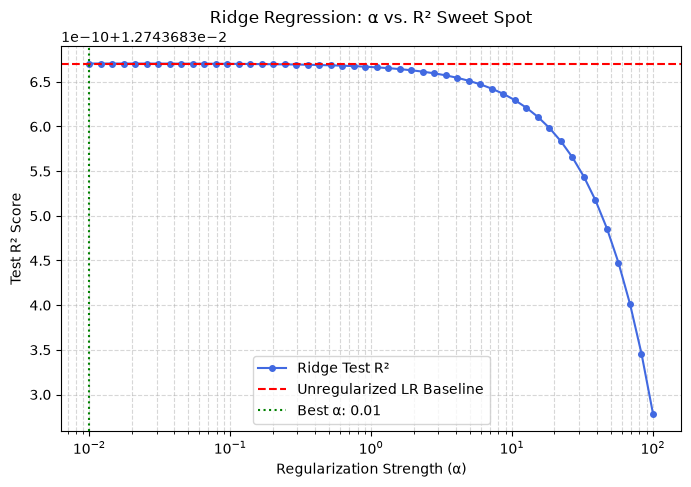

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score

# ==========================================
# 1. Load Dataset & Train-Test Split
# ==========================================
df = pd.read_csv('C:/Users/Pydis/Downloads/cp_data_demo.csv')

# Use Temperature to predict Heat_Capacity
X = df[['Temperature']]
y = df['Heat_Capacity']

# Ensure no NaN values exist
valid_mask = (~X['Temperature'].isna()) & (~y.isna())
X = X.loc[valid_mask]
y = y.loc[valid_mask]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# ==========================================
# 2. Unregularized Linear Regression Baseline
# ==========================================
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_train_r2 = r2_score(y_train, lr.predict(X_train))
lr_test_r2 = r2_score(y_test, lr.predict(X_test))
print(f"Linear Regression - Train R²: {lr_train_r2:.3f}, Test R²: {lr_test_r2:.3f}")

# ==========================================
# 3. Ridge Regression & Alpha Sweep (0.01 to 100)
# ==========================================
alphas = np.logspace(-2, 2, 50)
ridge_test_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    ridge_test_scores.append(r2_score(y_test, ridge.predict(X_test)))

# Find the best alpha
best_alpha = alphas[np.argmax(ridge_test_scores)]
best_score = max(ridge_test_scores)
print(f"Optimal Ridge α: {best_alpha:.2f} (Test R²: {best_score:.3f})")

# ==========================================
# 4. Plotting the Alpha Sweep
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(alphas, ridge_test_scores, marker='o', markersize=4, color='royalblue', label='Ridge Test R²')
plt.axhline(lr_test_r2, color='red', linestyle='--', label='Unregularized LR Baseline')
plt.axvline(best_alpha, color='green', linestyle=':', label=f'Best α: {best_alpha:.2f}')

plt.xscale('log')
plt.xlabel('Regularization Strength (α)')
plt.ylabel('Test R² Score')
plt.title('Ridge Regression: α vs. R² Sweet Spot')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

# Save the deliverable
plt.savefig('ridge_alpha_sweep.png', dpi=300, bbox_inches='tight')
print("✅ Alpha-sweep plot successfully saved.")
plt.show()